ˆ
𝛉 = (X⊺X)−1X⊺y

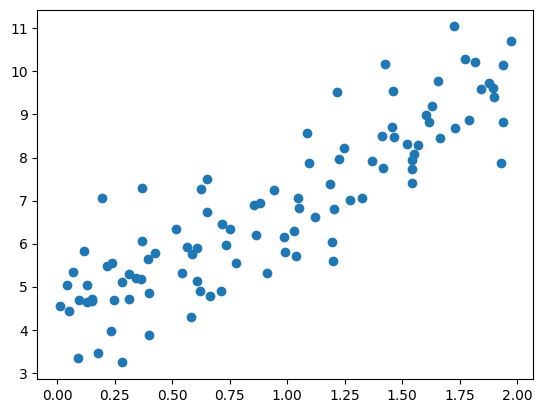

In [2]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
m=100
X = 2 * np.random.rand(m,1)
Y= 4+3*X + np.random.randn(m,1)
plt.scatter(X,Y)
plt.show()

In [3]:
from sklearn.preprocessing import add_dummy_feature

X_b = add_dummy_feature(X)
theta_best = np.linalg.inv(X_b.T @ X_b) @ X_b.T @ Y
print(theta_best)

[[4.21509616]
 [2.77011339]]


here the real value is 4 and 3 it close enough but the gaussian noise made it impossible to know the exact value

In [4]:
X_new = np.array([[0],[2]])
X_new_b = add_dummy_feature(X_new)
y_predict = X_new_b @ theta_best
y_predict

array([[4.21509616],
       [9.75532293]])

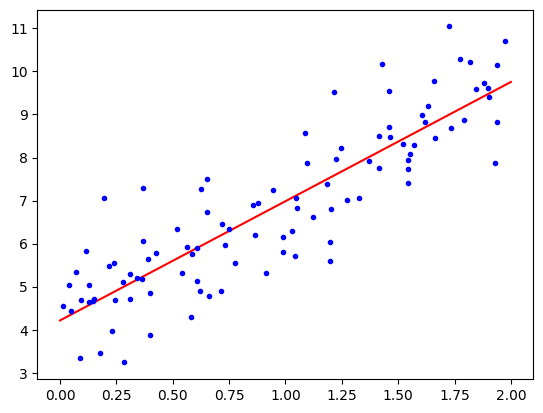

In [5]:

plt.plot(X_new, y_predict, "r-", label="Predictions")
plt.plot(X, Y, "b.")
plt.show()

In [6]:
from sklearn.linear_model import LinearRegression

lin_reg = LinearRegression()
lin_reg.fit(X,Y)
lin_reg.intercept_,lin_reg.coef_

(array([4.21509616]), array([[2.77011339]]))

In [7]:
lin_reg.predict(X_new)

array([[4.21509616],
       [9.75532293]])

coef does not include the bias

In [8]:
np.linalg.pinv(X_b) @ Y

array([[4.21509616],
       [2.77011339]])

the pseudoinverse use SVD that handle the expection very good ,the method normal need X.t @ X to be invertible

and also in complexity svd is about O(n**2) but the normal method need to inverse the matrix that is go between O(n**2,4) and O(n**3)

In [9]:
eta = 0.1
n_epochs = 1000
m = len(X_b)

np.random.seed(42)
theta = np.random.randn(2,1)
for epoch in range(n_epochs):
    gradients = 2/m * X_b.T @ (X_b @ theta-Y)
    theta-=eta * gradients

theta

array([[4.21509616],
       [2.77011339]])

In [11]:
n_epochs = 50
t0,t1 = 5,50

def learning_schedule(t):
    return t0/(t+t1)

np.random.seed(42)
theta = np.random.randn(2,1)

for epoch in range(n_epochs):
    for iteration in range(m):
        random_index = np.random.randint(m)
        xi = X_b[random_index:random_index+1]
        yi = Y[random_index:random_index+1]
        gradients = 2 * xi.T @ (xi @ theta-yi)
        eta = learning_schedule(m*epoch + iteration)
        theta -= eta * gradients
theta


array([[4.21076011],
       [2.74856079]])

In [13]:
from sklearn.linear_model import SGDRegressor

sgd_reg = SGDRegressor(tol=1e-5,eta0=0.01,penalty=None,max_iter=1000,n_iter_no_change=100)
sgd_reg.fit(X_b,Y.ravel())

sgd_reg.intercept_ , sgd_reg.coef_

(array([2.10740242]), array([2.10740242, 2.77002913]))